# Customer Spend Drivers in Retail
**Data Analytics for Managers using Python: Individual Assignment (Python, SQL & Portfolio)**

Name: Palak Singhal | Roll No: 26-PGDM083

**Business problem:** a grocery and wine retailer spreads marketing money evenly, but customers spend very differently.

**Key business question:** which customer characteristics are linked with higher total spend over two years, and does the effect of income depend on children at home and on web browsing?

**Outcome (Y):** Total_Spend over two years.  
**Dataset:** Customer Personality Analysis (Kaggle, marketing_campaign.csv). Add link and licence from the Kaggle page.

# Part 1. Load the data

In [1]:
# 1. import libraries
import os, sqlite3, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
print("welcome to business analytics")

welcome to business analytics


In [3]:
# 2. find the data file (Colab, Kaggle or local folder)
paths = ['/content/marketing_campaign.csv',
         '/content/marketing_campaign (1).csv',
         '/kaggle/input/customer-personality-analysis/marketing_campaign.csv',
         'marketing_campaign.csv', 'data/marketing_campaign.csv']
FILE = next(p for p in paths if os.path.exists(p))

# sep=None lets pandas detect ';' or tab; utf-8-sig removes a hidden BOM in the header
raw = pd.read_csv(FILE, sep=None, engine='python', encoding='utf-8-sig')
print("Loaded:", raw.shape[0], "customers and", raw.shape[1], "variables")

Loaded: 2240 customers and 29 variables


In [4]:
# 3. first look
raw.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


In [5]:
# 4. shape and data types
print("Shape:", raw.shape)
print(raw.dtypes.value_counts())

Shape: (2240, 29)
int64      25
object      3
float64     1
Name: count, dtype: int64


In [6]:
# 5. missing values
missing = raw.isna().sum()
print(missing[missing > 0])

Income    24
dtype: int64


In [7]:
# 6. duplicate rows (ignoring the ID column)
dupcols = [c for c in raw.columns if c != 'ID']
print("Duplicate rows:", raw.duplicated(subset=dupcols).sum())

Duplicate rows: 182


In [8]:
# 7. messy category labels
print(raw['Education'].value_counts())
print()
print(raw['Marital_Status'].value_counts())

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


## Business relevance of the variables
| Variable | Type | Role | Why it matters |
|---|---|---|---|
| Total_Spend | Numeric | Outcome (Y) | Customer value over two years |
| Income | Numeric | Predictor | Spending power |
| Children (Kidhome + Teenhome) | Numeric | Predictor | Dependants share the same budget |
| NumWebVisitsMonth | Numeric | Predictor | Browsing: interest or price-checking? |
| NumDealsPurchases | Numeric | Predictor | Discount sensitivity |
| Age, Recency, Tenure_Months | Numeric | Control | Life stage, engagement, time as customer |
| Education (4 groups) | Categorical | Predictor | Targeting segment (base: Graduation) |
| Marital_Status (4 groups) | Categorical | Predictor | Household type (base: Partner) |

# Part 2. Python: cleaning, EDA and charts
## Step 1. New variables

In [9]:
# 8. date and age (data ends in mid-2014)
df = raw.copy()
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'])
df['Age'] = 2014 - df['Year_Birth']

In [10]:
# 9. total spend = sum of the six product categories
spend_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
df['Total_Spend'] = df[spend_cols].sum(axis=1)
print(df['Total_Spend'].describe())

count    2240.000000
mean      605.798214
std       602.249288
min         5.000000
25%        68.750000
50%       396.000000
75%      1045.500000
max      2525.000000
Name: Total_Spend, dtype: float64


In [11]:
# 10. children at home, tenure and income in thousands
df['Children'] = df['Kidhome'] + df['Teenhome']
df['Tenure_Months'] = (pd.Timestamp('2014-06-30') - df['Dt_Customer']).dt.days / 30.44
df['Income_K'] = df['Income'] / 1000
df[['Age', 'Total_Spend', 'Children', 'Tenure_Months', 'Income_K']].head()

,Age,Total_Spend,Children,Tenure_Months,Income_K
0,57,1617,0,21.813403,58.138
1,60,27,2,3.745072,46.344
2,49,776,0,10.282523,71.613
3,30,53,1,4.599212,26.646
4,33,422,1,5.321945,58.293


In [12]:
# 11. tidy the category labels
df['Marital_Status'] = df['Marital_Status'].replace({'Alone': 'Single', 'Absurd': 'Single', 'YOLO': 'Single',
                                                      'Together': 'Partner', 'Married': 'Partner'})
df['Education'] = df['Education'].replace({'2n Cycle': 'Master'})   # 2n Cycle = Master level
print(df['Marital_Status'].value_counts())
print(df['Education'].value_counts())

Marital_Status
Partner     1444
Single       487
Divorced     232
Widow         77
Name: count, dtype: int64
Education
Graduation    1127
Master         573
PhD            486
Basic           54
Name: count, dtype: int64


## Step 2. Outliers (IQR rule)

In [13]:
# 12. IQR fences for key variables (before cleaning)
for c in ['Income', 'Age', 'Total_Spend', 'NumWebVisitsMonth', 'NumDealsPurchases']:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[c] < low) | (df[c] > high)).sum()
    print(c, "| fences:", round(low, 1), "to", round(high, 1), "| outliers:", n_out)

Income | fences: -14525.5 to 118350.5 | outliers: 8
Age | fences: 10.0 to 82.0 | outliers: 3
Total_Spend | fences: -1396.4 to 2510.6 | outliers: 3
NumWebVisitsMonth | fences: -3.0 to 13.0 | outliers: 8
NumDealsPurchases | fences: -2.0 to 6.0 | outliers: 86


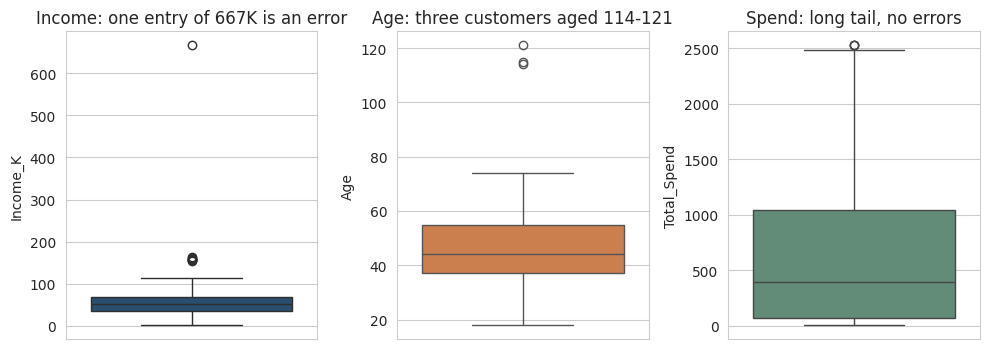

In [14]:
# 13. box plots before cleaning
fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))
sns.boxplot(y=df['Income_K'], ax=ax[0], color='#1F4E79')
ax[0].set_title('Income: one entry of 667K is an error')
sns.boxplot(y=df['Age'], ax=ax[1], color='#E07B39')
ax[1].set_title('Age: three customers aged 114-121')
sns.boxplot(y=df['Total_Spend'], ax=ax[2], color='#5B9279')
ax[2].set_title('Spend: long tail, no errors')
plt.tight_layout()
plt.show()

**Cleaning decisions**
- **Duplicates:** 182 rows are identical on every field except ID, so they are repeated records and are dropped.
- **Impossible values:** 3 customers aged 114-121 and one income of 666,666 are data-entry errors and are removed. Other IQR outliers are real customers and are kept.
- **Missing income:** 24 rows (about 1%) are dropped because income is the key predictor.

In [15]:
# 14. clean the data
df = df[~raw.duplicated(subset=dupcols)]            # drop duplicates
df = df[(df['Age'] <= 90) & (df['Income'].fillna(0) < 600000)]   # drop impossible values
df = df.dropna(subset=['Income']).copy()            # drop missing income
df['Has_Children'] = (df['Children'] > 0).astype(int)
df['Income_Band'] = pd.qcut(df['Income'], 4, labels=['Q1 Low', 'Q2', 'Q3', 'Q4 High'])
print("Clean sample:", df.shape[0], "customers")

Clean sample: 2030 customers


## Step 3. Descriptive statistics

In [16]:
# 15. mean, std, min, quartiles, max
num_cols = ['Income', 'Age', 'Recency', 'Tenure_Months', 'Children', 'NumWebVisitsMonth', 'NumDealsPurchases',
            'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases'] + spend_cols + ['Total_Spend']
df[num_cols].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Income,2030.0,52043.7,21591.4,1730.0,35461.5,51523.5,68445.8,162397.0
Age,2030.0,45.1,11.7,18.0,37.0,44.0,55.0,74.0
Recency,2030.0,48.9,29.0,0.0,24.0,49.0,74.0,99.0
Tenure_Months,2030.0,11.6,6.7,0.0,5.9,11.6,17.4,23.0
Children,2030.0,1.0,0.7,0.0,0.0,1.0,1.0,3.0
NumWebVisitsMonth,2030.0,5.3,2.4,0.0,3.0,6.0,7.0,20.0
NumDealsPurchases,2030.0,2.3,1.9,0.0,1.0,2.0,3.0,15.0
NumWebPurchases,2030.0,4.1,2.8,0.0,2.0,4.0,6.0,27.0
NumCatalogPurchases,2030.0,2.7,2.9,0.0,0.0,2.0,4.0,28.0
NumStorePurchases,2030.0,5.8,3.2,0.0,3.0,5.0,8.0,13.0


In [17]:
# 16. categorical variables: count and most common group
for c in ['Education', 'Marital_Status']:
    vc = df[c].value_counts()
    print(c, "| groups:", vc.size, "| most common:", vc.index[0], "(", vc.iloc[0], "customers )")
print("Skewness of Total_Spend:", round(df['Total_Spend'].skew(), 2))

Education | groups: 4 | most common: Graduation ( 1018 customers )
Marital_Status | groups: 4 | most common: Partner ( 1300 customers )
Skewness of Total_Spend: 0.86


**Meaning:** the average spend is about 608 but the median is 397, so a few big spenders pull the average up. Plan for different customer groups, not the "average customer". Wine is 50.2% of all spend and meat is 27.6%.

## Step 4. Data visualisation

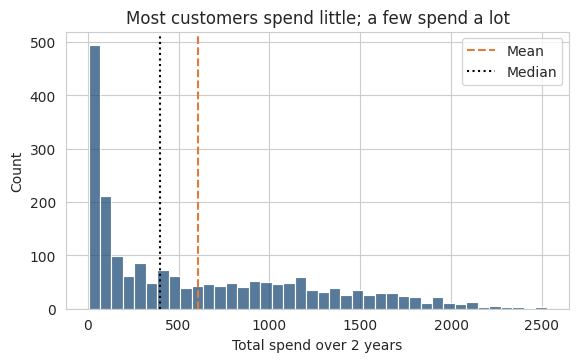

In [18]:
# 17. chart 1: how is spend distributed?
plt.figure(figsize=(6.5, 3.6))
sns.histplot(df['Total_Spend'], bins=40, color='#1F4E79')
plt.axvline(df['Total_Spend'].mean(), color='#E07B39', ls='--', label='Mean')
plt.axvline(df['Total_Spend'].median(), color='k', ls=':', label='Median')
plt.title('Most customers spend little; a few spend a lot')
plt.xlabel('Total spend over 2 years')
plt.legend()
plt.show()

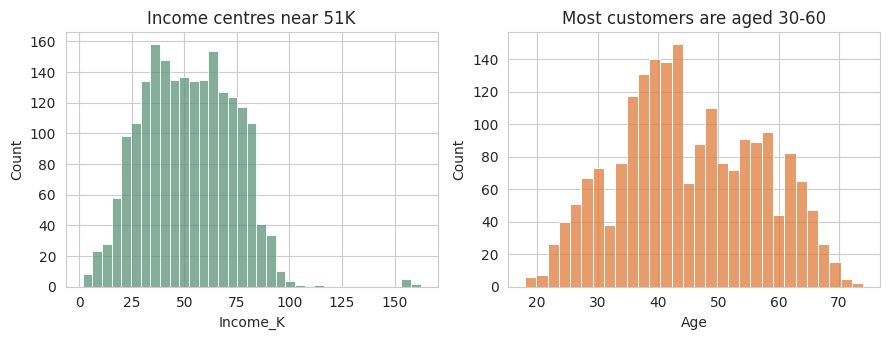

In [19]:
# 18. chart 2: income and age distributions
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
sns.histplot(df['Income_K'], bins=35, ax=ax[0], color='#5B9279')
ax[0].set_title('Income centres near 51K')
sns.histplot(df['Age'], bins=30, ax=ax[1], color='#E07B39')
ax[1].set_title('Most customers are aged 30-60')
plt.tight_layout()
plt.show()

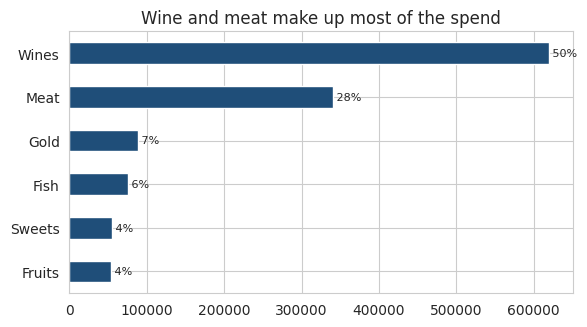

In [20]:
# 19. chart 3: where does the money go?
cat_tot = df[spend_cols].sum().sort_values()
cat_tot.index = ['Fruits', 'Sweets', 'Fish', 'Gold', 'Meat', 'Wines']
ax = cat_tot.plot.barh(color='#1F4E79', figsize=(6.5, 3.4))
for i, v in enumerate(cat_tot):
    ax.text(v, i, ' ' + str(round(100 * v / cat_tot.sum())) + '%', va='center', fontsize=8)
plt.title('Wine and meat make up most of the spend')
plt.show()

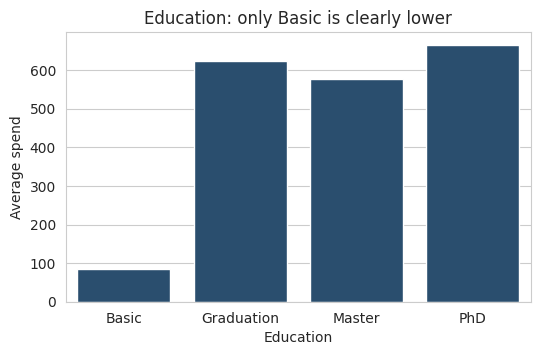

Education
Basic          83.9
Graduation    624.0
Master        576.7
PhD           665.1
Name: Total_Spend, dtype: float64


In [21]:
# 20. chart 4: spend by education
g = df.groupby('Education')['Total_Spend'].mean().reindex(['Basic', 'Graduation', 'Master', 'PhD'])
plt.figure(figsize=(6, 3.5))
sns.barplot(x=g.index, y=g.values, color='#1F4E79')
plt.title('Education: only Basic is clearly lower')
plt.ylabel('Average spend')
plt.show()
print(g.round(1))

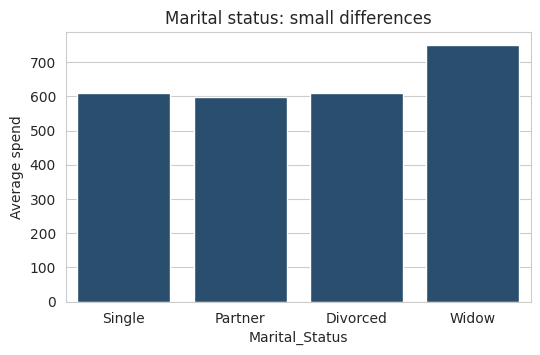

Marital_Status
Single      610.6
Partner     599.2
Divorced    608.3
Widow       750.3
Name: Total_Spend, dtype: float64


In [22]:
# 21. chart 5: spend by marital status
g = df.groupby('Marital_Status')['Total_Spend'].mean().reindex(['Single', 'Partner', 'Divorced', 'Widow'])
plt.figure(figsize=(6, 3.5))
sns.barplot(x=g.index, y=g.values, color='#1F4E79')
plt.title('Marital status: small differences')
plt.ylabel('Average spend')
plt.show()
print(g.round(1))

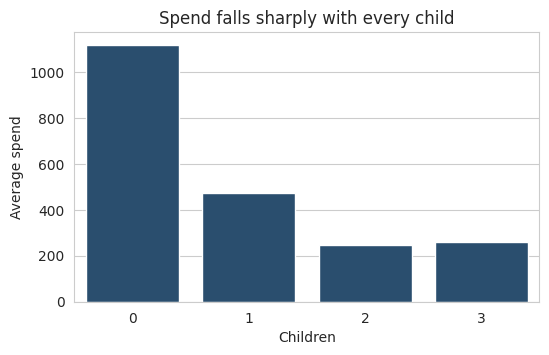

Children
0    1118.7
1     473.6
2     248.7
3     258.6
Name: Total_Spend, dtype: float64


In [23]:
# 22. chart 6: spend by number of children
g = df.groupby('Children')['Total_Spend'].mean()
plt.figure(figsize=(6, 3.5))
sns.barplot(x=g.index, y=g.values, color='#1F4E79')
plt.title('Spend falls sharply with every child')
plt.ylabel('Average spend')
plt.show()
print(g.round(1))

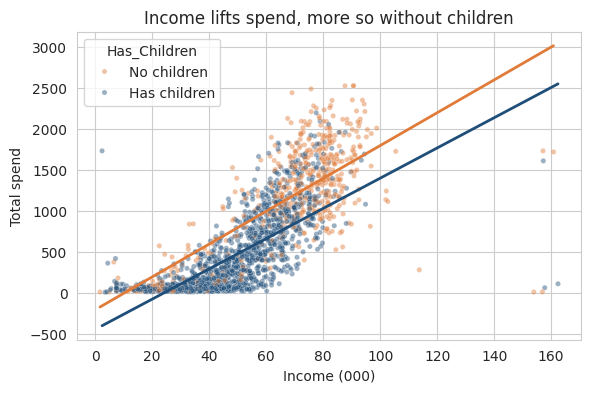

In [24]:
# 23. chart 7: income vs spend, with and without children
label = df['Has_Children'].map({0: 'No children', 1: 'Has children'})
plt.figure(figsize=(6.5, 4))
sns.scatterplot(data=df, x='Income_K', y='Total_Spend', hue=label, hue_order=['No children', 'Has children'],
                palette={'No children': '#E07B39', 'Has children': '#1F4E79'}, alpha=0.45, s=14)
for h, colour in [(0, '#E07B39'), (1, '#1F4E79')]:
    part = df[df['Has_Children'] == h]
    b = np.polyfit(part['Income_K'], part['Total_Spend'], 1)
    xs = np.linspace(part['Income_K'].min(), part['Income_K'].max(), 50)
    plt.plot(xs, np.polyval(b, xs), color=colour, lw=2)
plt.title('Income lifts spend, more so without children')
plt.xlabel('Income (000)')
plt.ylabel('Total spend')
plt.show()

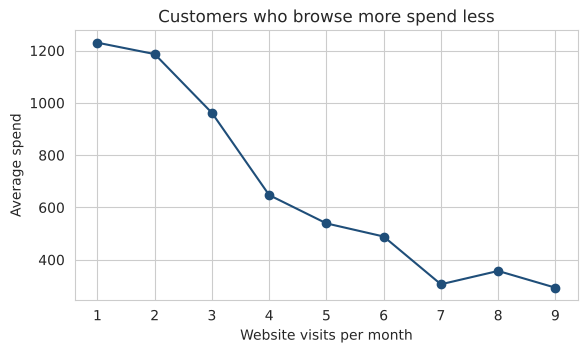

In [ ]:
# 24. chart 8: web visits vs spend
wv = df.groupby('NumWebVisitsMonth')['Total_Spend'].agg(['mean', 'count'])
wv = wv[wv['count'] >= 15]
plt.figure(figsize=(6.5, 3.5))
plt.plot(wv.index, wv['mean'], marker='o', color='#1F4E79')
plt.title('Customers who browse more spend less')
plt.xlabel('Website visits per month')
plt.ylabel('Average spend')
plt.show()

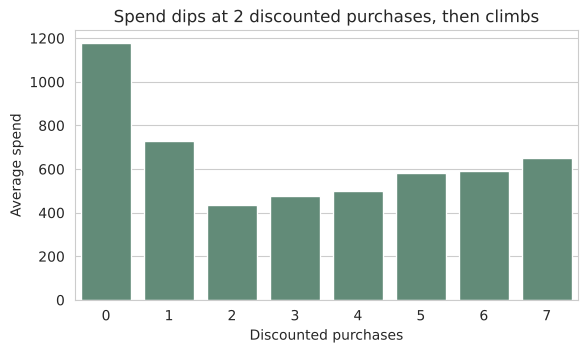

In [ ]:
# 25. chart 9: discounted purchases vs spend
dp = df.groupby('NumDealsPurchases')['Total_Spend'].agg(['mean', 'count'])
dp = dp[dp['count'] >= 15]
plt.figure(figsize=(6.5, 3.5))
sns.barplot(x=dp.index, y=dp['mean'], color='#5B9279')
plt.title('Spend dips at 2 discounted purchases, then climbs')
plt.xlabel('Discounted purchases')
plt.ylabel('Average spend')
plt.show()

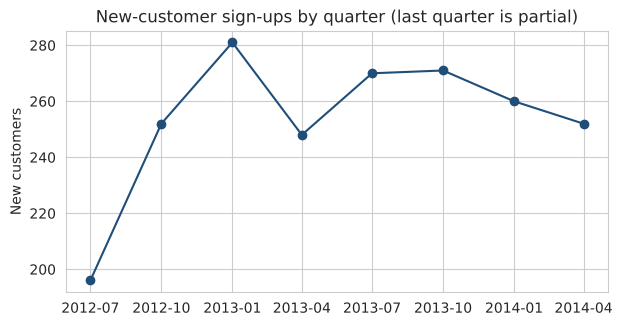

In [ ]:
# 26. chart 10: sign-up trend by quarter
sg = df.set_index('Dt_Customer').resample('QS').size()
plt.figure(figsize=(7, 3.4))
plt.plot(sg.index, sg.values, marker='o', color='#1F4E79')
plt.title('New-customer sign-ups by quarter (last quarter is partial)')
plt.ylabel('New customers')
plt.show()

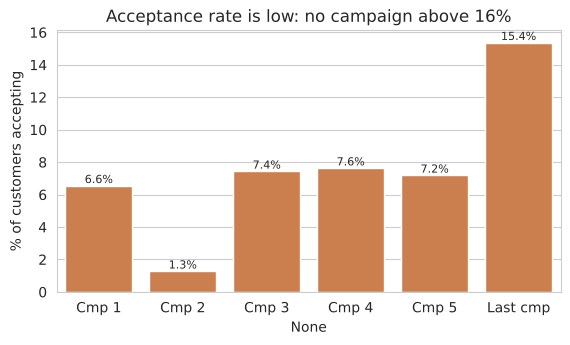

In [ ]:
# 27. chart 11: campaign acceptance
camp = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Response']
rate = df[camp].mean() * 100
rate.index = ['Cmp 1', 'Cmp 2', 'Cmp 3', 'Cmp 4', 'Cmp 5', 'Last cmp']
plt.figure(figsize=(6.5, 3.4))
ax = sns.barplot(x=rate.index, y=rate.values, color='#E07B39')
for i, v in enumerate(rate.values):
    ax.text(i, v, str(round(v, 1)) + '%', ha='center', va='bottom', fontsize=8)
plt.title('Acceptance rate is low: no campaign above 16%')
plt.ylabel('% of customers accepting')
plt.show()

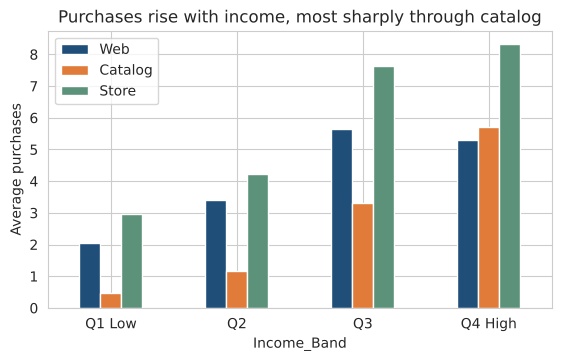

In [ ]:
# 28. chart 12: purchases by channel and income band
ch = df.groupby('Income_Band', observed=True)[['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']].mean()
ch.columns = ['Web', 'Catalog', 'Store']
ch.plot(kind='bar', figsize=(6.5, 3.6), color=['#1F4E79', '#E07B39', '#5B9279'])
plt.title('Purchases rise with income, most sharply through catalog')
plt.ylabel('Average purchases')
plt.xticks(rotation=0)
plt.show()

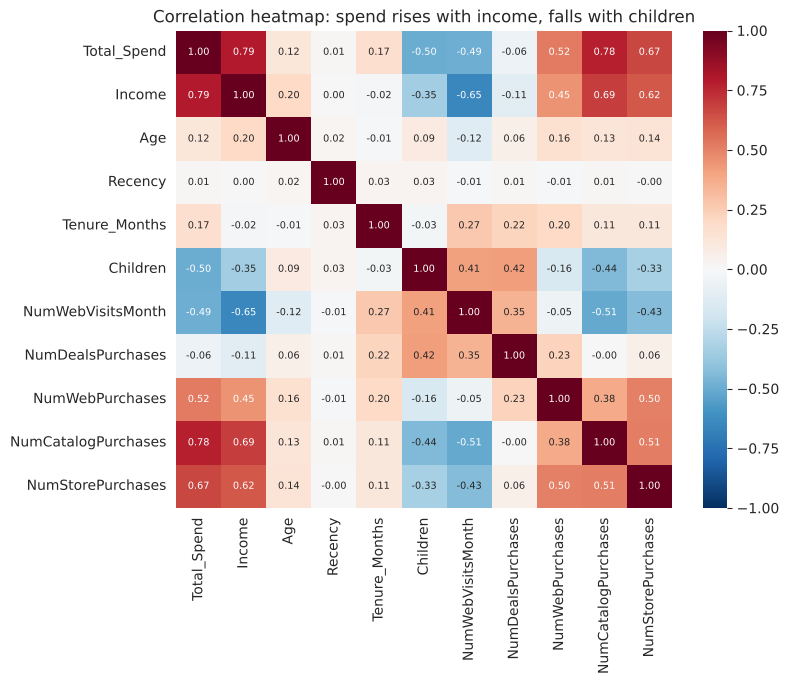

In [ ]:
# 29. chart 13: correlation heatmap
key_cols = ['Total_Spend', 'Income', 'Age', 'Recency', 'Tenure_Months', 'Children', 'NumWebVisitsMonth',
            'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
corr = df[key_cols].corr().round(2)
plt.figure(figsize=(8, 6.2))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, annot_kws={'size': 7})
plt.title('Correlation heatmap: spend rises with income, falls with children')
plt.show()

**Patterns found**
- Income has the strongest link with spend (correlation 0.79); children come next and are negative (-0.50).
- Average spend is 1119 with no children, 474 with one and 249 with two.
- Education and marital status differ little, except the tiny Basic education group (n=49).
- Web visits are negatively linked with spend (-0.49) because low-income households browse more (income and visits correlate at -0.65).
- Deal use alone is almost unrelated to spend (-0.06).
- Campaign acceptance is low everywhere; the last campaign did best (15.4%).

# Part 3. Multiple linear regression
## Model 1: without interaction
**Y:** Total_Spend. **Numeric X:** Income, Age, Recency, web visits, deal purchases, tenure, children. **Categorical X:** Education (base Graduation) and Marital_Status (base Partner), which enter as 0/1 dummy variables.

Income, age and web visits are centred (minus their average) so the intercept describes the average customer and the interaction terms are easier to read.

In [ ]:
# 30. centre the numeric variables
for c in ['Income_K', 'NumWebVisitsMonth', 'Age']:
    df[c + '_c'] = df[c] - df[c].mean()
df[['Income_K_c', 'NumWebVisitsMonth_c', 'Age_c']].mean().round(6)

Income_K_c            -0.0
NumWebVisitsMonth_c    0.0
Age_c                 -0.0

In [ ]:
# 31. fit Model 1
f1 = ("Total_Spend ~ Income_K_c + Age_c + Recency + NumWebVisitsMonth_c + NumDealsPurchases + Tenure_Months + Children"
      " + C(Education, Treatment('Graduation')) + C(Marital_Status, Treatment('Partner'))")
model1 = smf.ols(f1, data=df).fit()
print("Observations:", len(df))
print("R-squared:", round(model1.rsquared, 3), "| Adjusted R-squared:", round(model1.rsquared_adj, 3))

Observations: 2030
R-squared: 0.718 | Adjusted R-squared: 0.716


In [ ]:
# 32. Model 1 coefficient table
table1 = pd.DataFrame({'coef': model1.params, 'std err': model1.bse, 't': model1.tvalues, 'p-value': model1.pvalues})
table1.round(3)

                                                        coef  std err       t  p-value
Intercept                                            607.246   24.652  24.633    0.000
Income_K_c                                            19.668    0.475  41.433    0.000
Age_c                                                  0.260    0.652   0.400    0.690
Recency                                                0.300    0.247   1.215    0.225
NumWebVisitsMonth_c                                    3.987    4.392   0.908    0.364
NumDealsPurchases                                     34.783    4.324   8.044    0.000
Tenure_Months                                         12.659    1.175  10.769    0.000
Children                                            -249.568   11.738 -21.262    0.000
C(Education, Treatment('Graduation'))[T.Basic]        26.037   48.956   0.532    0.595
C(Education, Treatment('Graduation'))[T.Master]      -20.109   17.363  -1.158    0.247
C(Education, Treatment('Graduation'))[T.PhD

In [ ]:
# 33. multicollinearity check (VIF): all should be below 5
num_x = ['Income_K_c', 'Age_c', 'Recency', 'NumWebVisitsMonth_c', 'NumDealsPurchases', 'Tenure_Months', 'Children']
for c in num_x:
    others = [x for x in num_x if x != c]
    r2 = smf.ols(c + " ~ " + " + ".join(others), data=df).fit().rsquared
    print(c, round(1 / (1 - r2), 2))

Income_K_c 1.93
Age_c 1.08
Recency 1.0
NumWebVisitsMonth_c 2.24
NumDealsPurchases 1.37
Tenure_Months 1.19
Children 1.49


**Reading Model 1** (R-squared 0.718, adjusted 0.716)
- **Income:** 1,000 more income is linked with about 19.7 more spend (p < 0.001), others fixed.
- **Children:** each extra child is linked with about 250 less spend (p < 0.001).
- **Deal purchases:** each extra discounted purchase is linked with about 35 more spend (p < 0.001), but only once income and children are held fixed.
- **Tenure:** each extra month as a customer is linked with about 12.7 more spend (p < 0.001).
- **Not significant (p > 0.05):** age, recency, web visits and all education and marital-status dummies.

## Model 2: with interaction
**Why these interactions?**
1. **Income x Children:** a household with children must spend part of its income on other needs, so extra income should lift grocery spend less than for a household without children.
2. **Income x Web visits:** browsing by a high-income customer is more likely to become a purchase, while low-income browsing is more likely price-checking.

In [ ]:
# 34. fit Model 2 (Model 1 + two interaction terms)
f2 = f1 + " + Income_K_c:Children + Income_K_c:NumWebVisitsMonth_c"
model2 = smf.ols(f2, data=df).fit()
print("R-squared:", round(model2.rsquared, 3), "| Adjusted R-squared:", round(model2.rsquared_adj, 3))

R-squared: 0.738 | Adjusted R-squared: 0.736


In [ ]:
# 35. Model 2 coefficient table
table2 = pd.DataFrame({'coef': model2.params, 'std err': model2.bse, 't': model2.tvalues, 'p-value': model2.pvalues})
table2.round(3)

                                                        coef  std err       t  p-value
Intercept                                            653.562   25.143  25.994    0.000
Income_K_c                                            25.223    0.646  39.015    0.000
Age_c                                                 -0.086    0.630  -0.136    0.892
Recency                                                0.375    0.238   1.578    0.115
NumWebVisitsMonth_c                                   20.794    4.449   4.674    0.000
NumDealsPurchases                                     41.766    4.214   9.912    0.000
Tenure_Months                                         10.885    1.145   9.508    0.000
Children                                            -290.742   11.902 -24.427    0.000
C(Education, Treatment('Graduation'))[T.Basic]        88.774   47.448   1.871    0.061
C(Education, Treatment('Graduation'))[T.Master]      -20.875   16.735  -1.247    0.212
C(Education, Treatment('Graduation'))[T.PhD

In [ ]:
# 36. income effect for 0, 1 and 2 children
b = model2.params
for k in [0, 1, 2]:
    slope = b['Income_K_c'] + b['Income_K_c:Children'] * k
    print("Children =", k, "-> income effect per 1,000:", round(slope, 1))

Children = 0 -> income effect per 1,000: 25.2
Children = 1 -> income effect per 1,000: 19.4
Children = 2 -> income effect per 1,000: 13.7


In [ ]:
# 37. income effect at low and high web visits
mean_web = df['NumWebVisitsMonth'].mean()
for v in [2, 8]:
    slope = b['Income_K_c'] + b['Income_K_c:NumWebVisitsMonth_c'] * (v - mean_web)
    print("Web visits =", v, "-> income effect per 1,000:", round(slope, 1))

Web visits = 2 -> income effect per 1,000: 21.5
Web visits = 8 -> income effect per 1,000: 28.2


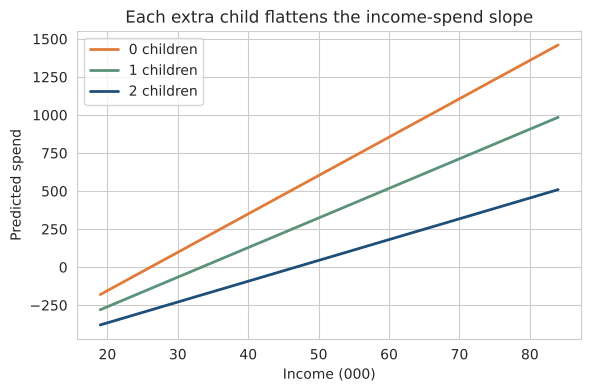

In [ ]:
# 38. interaction plot
mi = df['Income_K'].mean()
xs = np.linspace(df['Income_K'].quantile(0.05), df['Income_K'].quantile(0.95), 30)
plt.figure(figsize=(6.5, 4))
for k, colour in zip([0, 1, 2], ['#E07B39', '#5B9279', '#1F4E79']):
    y = b['Intercept'] + b['Income_K_c'] * (xs - mi) + b['Children'] * k + b['Income_K_c:Children'] * (xs - mi) * k
    plt.plot(xs, y, color=colour, lw=2, label=str(k) + ' children')
plt.title('Each extra child flattens the income-spend slope')
plt.xlabel('Income (000)')
plt.ylabel('Predicted spend')
plt.legend()
plt.show()

**Reading Model 2:** the income slope is about 25.2 per 1,000 with no children, 19.4 with one child and 13.7 with two. The Income x Children coefficient is -5.77 (p < 0.001): **the effect of income depends on household type.** The Income x Web visits coefficient is 1.13 (p < 0.001): income matters more for frequent site visitors (21.5 at 2 visits vs 28.2 at 8).

## Model comparison

In [ ]:
# 39. helper values for the comparison
def rmse(m):
    return float(np.sqrt((m.resid ** 2).mean()))

def mae(m):
    return float(m.resid.abs().mean())

def n_sig(m):
    return int((m.pvalues.drop('Intercept') < 0.05).sum())

# hold-out check: fit on 80% of customers, test on the other 20%
rng = np.random.RandomState(42)
idx = rng.permutation(len(df))
cut = int(0.8 * len(df))
train, test = df.iloc[idx[:cut]], df.iloc[idx[cut:]]

def holdout(formula):
    m = smf.ols(formula, data=train).fit()
    p = m.predict(test)
    return float(np.sqrt(((test['Total_Spend'] - p) ** 2).mean()))

In [ ]:
# 40. comparison table
comp = pd.DataFrame({
    'Model 1 (no interaction)': [model1.rsquared, model1.rsquared_adj, model1.aic, model1.bic, rmse(model1), mae(model1), holdout(f1), n_sig(model1)],
    'Model 2 (with interaction)': [model2.rsquared, model2.rsquared_adj, model2.aic, model2.bic, rmse(model2), mae(model2), holdout(f2), n_sig(model2)]},
    index=['R-squared', 'Adjusted R-squared', 'AIC', 'BIC', 'RMSE (in-sample)', 'MAE (in-sample)', 'RMSE (20% hold-out)', 'Significant predictors'])
comp.round(3)

                        Model 1 (no interaction)  Model 2 (with interaction)
R-squared                                  0.718                       0.738
Adjusted R-squared                         0.716                       0.736
AIC                                    29211.124                   29062.390
BIC                                    29289.745                   29152.243
RMSE (in-sample)                         320.225                     308.402
MAE (in-sample)                          228.981                     220.238
RMSE (20% hold-out)                      322.769                     313.294
Significant predictors                     4.000                       7.000

In [ ]:
# 41. F-statistics and nested F-test for the two interaction terms
print("F Model 1:", round(model1.fvalue, 1), "| F Model 2:", round(model2.fvalue, 1))
rss1, rss2 = (model1.resid ** 2).sum(), (model2.resid ** 2).sum()
F = ((rss1 - rss2) / 2) / (rss2 / model2.df_resid)
print("Nested F-test: F =", round(F, 2), "| p =", stats.f.sf(F, 2, model2.df_resid))

F Model 1: 394.8 | F Model 2: 379.0
Nested F-test: F = 78.69 | p = 1.246646037501681e-33


**Preferred model: Model 2.** Adjusted R-squared rises (0.716 to 0.736), AIC and BIC both fall, the error is lower in-sample and on unseen data, and the nested F-test confirms the interactions add real explanatory power. The gain is modest (2.0 percentage points of R-squared), but the interactions show that income is not equally valuable for every household. In Model 2 the income, web-visit and children coefficients are effects at *average* income and browsing (because of centring).

## Residual check

Customers with negative predicted spend: 222 of 2030


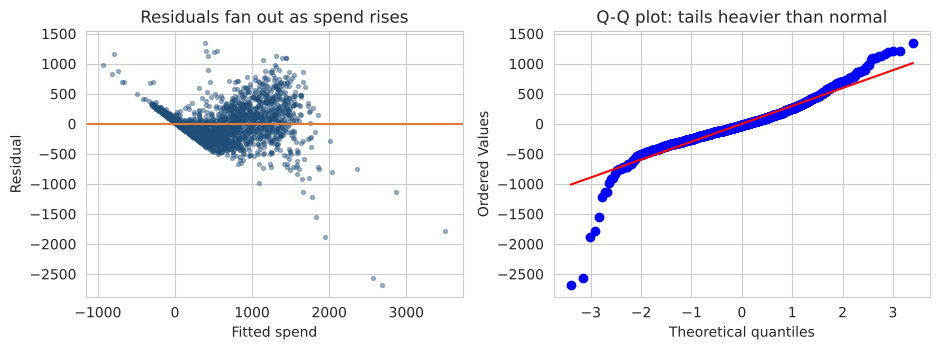

In [ ]:
# 42. residual plots
res, fitted = model2.resid, model2.fittedvalues
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6))
ax[0].scatter(fitted, res, s=8, alpha=0.4, color='#1F4E79')
ax[0].axhline(0, color='#E07B39')
ax[0].set_xlabel('Fitted spend')
ax[0].set_ylabel('Residual')
ax[0].set_title('Residuals fan out as spend rises')
stats.probplot(res, dist='norm', plot=ax[1])
ax[1].set_title('Q-Q plot: tails heavier than normal')
plt.tight_layout()
plt.show()
print("Customers with negative predicted spend:", int((fitted < 0).sum()), "of", len(df))

In [ ]:
# 43. robust (HC3) standard errors: do the conclusions hold?
robust = smf.ols(f2, data=df).fit(cov_type='HC3')
pd.DataFrame({'p classic': model2.pvalues, 'p robust (HC3)': robust.pvalues}).round(4)

                                                     p classic  p robust (HC3)
Intercept                                               0.0000          0.0000
Income_K_c                                              0.0000          0.0000
Age_c                                                   0.8917          0.9077
Recency                                                 0.1148          0.1302
NumWebVisitsMonth_c                                     0.0000          0.0008
NumDealsPurchases                                       0.0000          0.0000
Tenure_Months                                           0.0000          0.0000
Children                                                0.0000          0.0000
C(Education, Treatment('Graduation'))[T.Basic]          0.0615          0.0029
C(Education, Treatment('Graduation'))[T.Master]         0.2124          0.2036
C(Education, Treatment('Graduation'))[T.PhD]            0.5650          0.5983
C(Marital_Status, Treatment('Partner'))[T.Divorced] 

**Residual check:** the residuals are not random: the spread grows with fitted spend and the Q-Q plot shows heavy tails. With robust (HC3) errors the main conclusions hold; the only change is the small Basic education group (n=49), which becomes significant (p = 0.003), so treat it with caution. **Limit:** a straight-line model predicts negative spend for 222 customers, which is impossible; a log or two-part model would fit low spenders better.

**Correlation vs causation:** the model shows links in one snapshot, not causes. Children at home do not necessarily cause lower spend; other costs, shopping elsewhere or lifestyle may explain it.

## Business recommendations
1. **Target by income first, household second.** About 20 more spend per 1,000 income; childless households spend far more. Send premium wine and meat offers to high-income households without children and value packs to families.
2. **Do not treat web visits as buying intent.** Retarget high-income browsers, not every visitor.
3. **Read promotions with care.** Deal use alone is unrelated to spend; with income and children fixed each extra discounted purchase is linked with about 35 more spend.
4. **Do not segment on education or marital status alone.** They add little once income and children are known.
5. **Protect long-standing customers.** Tenure is linked with about 12.7 more spend per month.
6. **Make campaigns selective** and test with a control group.

**Limits:** one snapshot (no causation); negative predictions for some low spenders; uneven residuals; a few very high incomes with almost no spend may be errors; one retailer, 2012-2014.

# Part 4. SQL (SQLite)
The tables are built from the raw CSV (before cleaning) so NULL values exist for the NULL query. The same SQL is saved in `sql/01_schema.sql` and `sql/02_queries.sql`.

In [ ]:
# 44. create the three tables
con = sqlite3.connect(':memory:')
con.executescript('''
CREATE TABLE customers (customer_id INTEGER PRIMARY KEY, year_birth INTEGER NOT NULL, education TEXT NOT NULL,
    marital_status TEXT NOT NULL, income REAL, kidhome INTEGER DEFAULT 0 CHECK (kidhome >= 0),
    teenhome INTEGER DEFAULT 0 CHECK (teenhome >= 0), dt_customer TEXT NOT NULL, recency INTEGER, complain INTEGER DEFAULT 0);
CREATE TABLE spend (customer_id INTEGER PRIMARY KEY, mnt_wines REAL, mnt_fruits REAL, mnt_meat REAL, mnt_fish REAL,
    mnt_sweets REAL, mnt_gold REAL, num_deals INTEGER, num_web INTEGER, num_catalog INTEGER, num_store INTEGER,
    web_visits_month INTEGER, FOREIGN KEY (customer_id) REFERENCES customers(customer_id));
CREATE TABLE campaign_accepts (customer_id INTEGER NOT NULL, campaign_no INTEGER NOT NULL CHECK (campaign_no BETWEEN 1 AND 6),
    PRIMARY KEY (customer_id, campaign_no), FOREIGN KEY (customer_id) REFERENCES customers(customer_id));
''')
print("tables created")

tables created


In [ ]:
# 45. fill the tables from the CSV
r = raw.copy()
r['Dt_Customer'] = pd.to_datetime(r['Dt_Customer']).dt.strftime('%Y-%m-%d')

cust = r[['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'Complain']]
cust.columns = ['customer_id', 'year_birth', 'education', 'marital_status', 'income', 'kidhome', 'teenhome', 'dt_customer', 'recency', 'complain']
cust.to_sql('customers', con, if_exists='append', index=False)

sp = r[['ID', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
        'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth']]
sp.columns = ['customer_id', 'mnt_wines', 'mnt_fruits', 'mnt_meat', 'mnt_fish', 'mnt_sweets', 'mnt_gold',
              'num_deals', 'num_web', 'num_catalog', 'num_store', 'web_visits_month']
sp.to_sql('spend', con, if_exists='append', index=False)

# one row per ACCEPTED campaign only (customers who never accepted have no row)
acc = []
for n, c in enumerate(camp, 1):
    for i in r.loc[r[c] == 1, 'ID']:
        acc.append((int(i), n))
con.executemany('INSERT INTO campaign_accepts VALUES (?,?)', acc)
con.commit()
for t in ['customers', 'spend', 'campaign_accepts']:
    print(t, con.execute('SELECT COUNT(*) FROM ' + t).fetchone()[0], 'rows')

customers 2240 rows
spend 2240 rows
campaign_accepts 1001 rows


**Q1 | SELECT, ORDER BY, LIMIT**  
Business question: Who are our 10 highest-spending customers?

In [ ]:
# 46. Q1
q = """
SELECT c.customer_id, c.education, c.income,
       (s.mnt_wines + s.mnt_fruits + s.mnt_meat + s.mnt_fish + s.mnt_sweets + s.mnt_gold) AS total_spend
FROM customers c
JOIN spend s ON s.customer_id = c.customer_id
ORDER BY total_spend DESC
LIMIT 10;
"""
pd.read_sql(q, con)

   customer_id   education   income  total_spend
0         5350      Master  90638.0       2525.0
1         5735      Master  90638.0       2525.0
2         1763  Graduation  87679.0       2524.0
3         4580  Graduation  75759.0       2486.0
4         4475         PhD  69098.0       2440.0
5         5453      Master  90226.0       2352.0
6        10133  Graduation  93790.0       2349.0
7         9010      Master  83151.0       2346.0
8         5386  Graduation  94384.0       2302.0
9         6024  Graduation  94384.0       2302.0

*Interpretation:* The best customers are mid-to-high income. Two pairs of rows have identical values, which are the duplicates Python removed.

**Q2 | WHERE with AND, OR, IN, BETWEEN, LIKE**  
Business question: How many mid-income, postgraduate customers with a partner could form a premium wine campaign list?

In [ ]:
# 47. Q2
q = """
SELECT COUNT(*) AS target_customers
FROM customers c
JOIN spend s ON s.customer_id = c.customer_id
WHERE c.education IN ('Master', 'PhD', '2n Cycle')
  AND c.income BETWEEN 50000 AND 90000
  AND (c.marital_status LIKE 'Marr%' OR c.marital_status = 'Together')
  AND s.mnt_wines > 300;
"""
pd.read_sql(q, con)

   target_customers
0               257

*Interpretation:* 257 customers (about 11%) form a ready list for a premium wine campaign.

**Q3 | NULL handling: IS NULL, COALESCE**  
Business question: Do customers with a missing income behave differently, and what happens if we fill the gap with the average income?

In [ ]:
# 48. Q3
q = """
SELECT CASE WHEN c.income IS NULL THEN 'Income missing' ELSE 'Income recorded' END AS income_status,
       COUNT(*)                                                                    AS customers,
       ROUND(AVG(c.income), 0)                                                     AS avg_income_raw,
       ROUND(AVG(COALESCE(c.income, (SELECT AVG(income) FROM customers))), 0)     AS avg_income_filled,
       ROUND(AVG(s.mnt_wines + s.mnt_fruits + s.mnt_meat + s.mnt_fish + s.mnt_sweets + s.mnt_gold), 1) AS avg_spend
FROM customers c
JOIN spend s ON s.customer_id = c.customer_id
GROUP BY income_status;
"""
pd.read_sql(q, con)

     income_status  customers  avg_income_raw  avg_income_filled  avg_spend
0   Income missing         24             NaN            52247.0      487.9
1  Income recorded       2216         52247.0            52247.0      607.1

*Interpretation:* The 24 customers with no income spend about 20% less (487.9 vs 607.1). Filling with the average hides that, so Python drops them.

**Q4 | Functions: CASE WHEN, ROUND, strftime (date function)**  
Business question: How does spend differ across income bands and sign-up years?

In [ ]:
# 49. Q4
q = """
SELECT CASE WHEN c.income IS NULL     THEN 'Unknown'
            WHEN c.income < 35000     THEN '1 Low (<35K)'
            WHEN c.income < 70000     THEN '2 Mid (35-70K)'
            ELSE                           '3 High (70K+)' END   AS income_band,
       strftime('%Y', c.dt_customer)                            AS signup_year,
       COUNT(*)                                                 AS customers,
       ROUND(AVG(s.mnt_wines + s.mnt_fruits + s.mnt_meat + s.mnt_fish + s.mnt_sweets + s.mnt_gold), 1) AS avg_spend
FROM customers c
JOIN spend s ON s.customer_id = c.customer_id
GROUP BY income_band, signup_year
ORDER BY income_band, signup_year;
"""
pd.read_sql(q, con)

       income_band signup_year  customers  avg_spend
0     1 Low (<35K)        2012        127      117.9
1     1 Low (<35K)        2013        284       80.4
2     1 Low (<35K)        2014        138       45.1
3   2 Mid (35-70K)        2012        262      754.4
4   2 Mid (35-70K)        2013        623      508.6
5   2 Mid (35-70K)        2014        274      318.9
6    3 High (70K+)        2012        101     1517.0
7    3 High (70K+)        2013        266     1378.5
8    3 High (70K+)        2014        141     1273.0
9          Unknown        2012          4      609.0
10         Unknown        2013         16      566.8
11         Unknown        2014          4       51.3

*Interpretation:* Spend rises sharply with income band in every sign-up year; later sign-ups spend less because they had less time, which is why tenure is a control.

**Q5 | Aggregations: COUNT, SUM, AVG, MIN, MAX**  
Business question: What is the overall size and spread of customer spend?

In [ ]:
# 50. Q5
q = """
SELECT COUNT(*)                                                        AS customers,
       ROUND(SUM(mnt_wines + mnt_fruits + mnt_meat + mnt_fish + mnt_sweets + mnt_gold), 0) AS total_revenue,
       ROUND(AVG(mnt_wines + mnt_fruits + mnt_meat + mnt_fish + mnt_sweets + mnt_gold), 1) AS avg_spend,
       MIN(mnt_wines + mnt_fruits + mnt_meat + mnt_fish + mnt_sweets + mnt_gold)           AS min_spend,
       MAX(mnt_wines + mnt_fruits + mnt_meat + mnt_fish + mnt_sweets + mnt_gold)           AS max_spend
FROM spend;
"""
pd.read_sql(q, con)

   customers  total_revenue  avg_spend  min_spend  max_spend
0       2240      1356988.0      605.8        5.0     2525.0

*Interpretation:* Spend is very uneven (5 to 2,525; average 605.8).

**Q6 | GROUP BY + HAVING**  
Business question: Which education groups (with at least 100 customers) spend the most on average?

In [ ]:
# 51. Q6
q = """
SELECT c.education,
       COUNT(*)                                                                             AS customers,
       ROUND(AVG(s.mnt_wines + s.mnt_fruits + s.mnt_meat + s.mnt_fish + s.mnt_sweets + s.mnt_gold), 1) AS avg_spend,
       ROUND(AVG(c.income), 0)                                                              AS avg_income
FROM customers c
JOIN spend s ON s.customer_id = c.customer_id
GROUP BY c.education
HAVING COUNT(*) >= 100
ORDER BY avg_spend DESC;
"""
pd.read_sql(q, con)

    education  customers  avg_spend  avg_income
0         PhD        486      672.4     56145.0
1  Graduation       1127      619.9     52720.0
2      Master        370      611.8     52918.0
3    2n Cycle        203      496.5     47633.0

*Interpretation:* PhD spend most (672.4) and 2n Cycle least (496.5); the gaps are small compared with income and household effects.

**Q7 | INNER JOIN (key business question: household size and spend)**  
Business question: How much less do households with children spend?

In [ ]:
# 52. Q7
q = """
SELECT (c.kidhome + c.teenhome)                                                             AS children_at_home,
       COUNT(*)                                                                             AS customers,
       ROUND(AVG(s.mnt_wines + s.mnt_fruits + s.mnt_meat + s.mnt_fish + s.mnt_sweets + s.mnt_gold), 1) AS avg_spend,
       ROUND(AVG(c.income), 0)                                                              AS avg_income
FROM customers c
INNER JOIN spend s ON s.customer_id = c.customer_id
GROUP BY children_at_home
ORDER BY children_at_home;
"""
pd.read_sql(q, con)

   children_at_home  customers  avg_spend  avg_income
0                 0        638     1106.0     65706.0
1                 1       1128      472.7     47713.0
2                 2        421      245.9     44612.0
3                 3         53      274.6     46677.0

*Interpretation:* Spend drops from 1,106.0 with no children to 472.7 with one and 245.9 with two; part of the gap is lower family income.

**Q8 | LEFT JOIN**  
Business question: Do customers who never accept any campaign spend less than those who accept at least one?

In [ ]:
# 53. Q8
q = """
SELECT CASE WHEN a.customer_id IS NULL THEN 'Never accepted' ELSE 'Accepted 1+' END AS group_label,
       COUNT(DISTINCT c.customer_id)                                                   AS customers,
       ROUND(AVG(s.mnt_wines + s.mnt_fruits + s.mnt_meat + s.mnt_fish + s.mnt_sweets + s.mnt_gold), 1) AS avg_spend
FROM customers c
JOIN spend s ON s.customer_id = c.customer_id
LEFT JOIN campaign_accepts a ON a.customer_id = c.customer_id
GROUP BY group_label
ORDER BY avg_spend DESC;
"""
pd.read_sql(q, con)

      group_label  customers  avg_spend
0     Accepted 1+        609     1153.1
1  Never accepted       1631      458.1

*Interpretation:* Customers who accepted any campaign spend about 2.5 times more (1,153.1 vs 458.1), but this does not prove campaigns create spend.

**Q9 | Business link: spend by income band and household type**  
Business question: Is the income effect on spend weaker for households with children (the interaction used in the regression)?

In [ ]:
# 54. Q9
q = """
SELECT CASE WHEN c.income < 35000 THEN '1 Low (<35K)'
            WHEN c.income < 70000 THEN '2 Mid (35-70K)'
            ELSE '3 High (70K+)' END                                                    AS income_band,
       CASE WHEN c.kidhome + c.teenhome > 0 THEN 'With children' ELSE 'No children' END AS household,
       COUNT(*)                                                                         AS customers,
       ROUND(AVG(s.mnt_wines + s.mnt_fruits + s.mnt_meat + s.mnt_fish + s.mnt_sweets + s.mnt_gold), 1) AS avg_spend
FROM customers c
JOIN spend s ON s.customer_id = c.customer_id
WHERE c.income IS NOT NULL AND c.income < 600000
GROUP BY income_band, household
ORDER BY income_band, household;
"""
pd.read_sql(q, con)

      income_band      household  customers  avg_spend
0    1 Low (<35K)    No children        101      126.0
1    1 Low (<35K)  With children        448       69.9
2  2 Mid (35-70K)    No children        172      940.7
3  2 Mid (35-70K)  With children        987      445.9
4   3 High (70K+)    No children        360     1458.6
5   3 High (70K+)  With children        147     1185.2

*Interpretation:* In every income band childless households spend more; the gap is 494.8 in the mid band and 273.4 in the high band, matching the Income x Children interaction.

**Q10 | Business link: category mix by income band**  
Business question: What share of each income band's budget goes to wine versus everyday categories?

In [ ]:
# 55. Q10
q = """
SELECT CASE WHEN c.income < 35000 THEN '1 Low (<35K)'
            WHEN c.income < 70000 THEN '2 Mid (35-70K)'
            ELSE '3 High (70K+)' END                                                      AS income_band,
       ROUND(100.0 * SUM(s.mnt_wines) / SUM(s.mnt_wines + s.mnt_fruits + s.mnt_meat + s.mnt_fish + s.mnt_sweets + s.mnt_gold), 1) AS wine_pct,
       ROUND(100.0 * SUM(s.mnt_meat)  / SUM(s.mnt_wines + s.mnt_fruits + s.mnt_meat + s.mnt_fish + s.mnt_sweets + s.mnt_gold), 1) AS meat_pct,
       ROUND(100.0 * SUM(s.mnt_fruits + s.mnt_fish + s.mnt_sweets + s.mnt_gold) / SUM(s.mnt_wines + s.mnt_fruits + s.mnt_meat + s.mnt_fish + s.mnt_sweets + s.mnt_gold), 1) AS other_pct
FROM customers c
JOIN spend s ON s.customer_id = c.customer_id
WHERE c.income IS NOT NULL AND c.income < 600000
GROUP BY income_band
ORDER BY income_band;
"""
pd.read_sql(q, con)

      income_band  wine_pct  meat_pct  other_pct
0    1 Low (<35K)      26.6      27.8       45.6
1  2 Mid (35-70K)      56.3      22.0       21.8
2   3 High (70K+)      46.6      32.3       21.2

*Interpretation:* Mid-income customers put 56.3% into wine; high-income customers buy more meat (32.3%); low-income customers spend more on the small categories.

**Q11 | Subquery: customers above the average spend**  
Business question: What share of customers spend more than the average, and which channel do they use most?

In [ ]:
# 56. Q11
q = """
SELECT COUNT(*)                         AS above_avg_customers,
       ROUND(AVG(s.num_web), 2)         AS avg_web,
       ROUND(AVG(s.num_catalog), 2)     AS avg_catalog,
       ROUND(AVG(s.num_store), 2)       AS avg_store,
       ROUND(AVG(s.web_visits_month), 2) AS avg_web_visits
FROM spend s
WHERE (s.mnt_wines + s.mnt_fruits + s.mnt_meat + s.mnt_fish + s.mnt_sweets + s.mnt_gold) >
      (SELECT AVG(mnt_wines + mnt_fruits + mnt_meat + mnt_fish + mnt_sweets + mnt_gold) FROM spend);
"""
pd.read_sql(q, con)

   above_avg_customers  avg_web  avg_catalog  avg_store  avg_web_visits
0                  918     5.84         5.23       8.58            3.91

*Interpretation:* 918 customers (41%) spend above average; they buy mostly in store (8.58) and visit the website only 3.91 times a month.

**Q12 | Window function: top 3 spenders inside each education group**  
Business question: Who are the best customers in each education group for a loyalty programme?

In [ ]:
# 57. Q12
q = """
SELECT education, customer_id, total_spend, rank_in_group
FROM (
    SELECT c.education, c.customer_id,
           (s.mnt_wines + s.mnt_fruits + s.mnt_meat + s.mnt_fish + s.mnt_sweets + s.mnt_gold) AS total_spend,
           ROW_NUMBER() OVER (PARTITION BY c.education
                              ORDER BY (s.mnt_wines + s.mnt_fruits + s.mnt_meat + s.mnt_fish + s.mnt_sweets + s.mnt_gold) DESC) AS rank_in_group
    FROM customers c
    JOIN spend s ON s.customer_id = c.customer_id
)
WHERE rank_in_group <= 3
ORDER BY education, rank_in_group;
"""
pd.read_sql(q, con)

     education  customer_id  total_spend  rank_in_group
0     2n Cycle         2186       2257.0              1
1     2n Cycle         4947       2059.0              2
2     2n Cycle         3139       2052.0              3
3        Basic         1951        839.0              1
4        Basic         5043        434.0              2
5        Basic         8151        263.0              3
6   Graduation         1763       2524.0              1
7   Graduation         4580       2486.0              2
8   Graduation        10133       2349.0              3
9       Master         5350       2525.0              1
10      Master         5735       2525.0              2
11      Master         5453       2352.0              3
12         PhD         4475       2440.0              1
13         PhD          737       2231.0              2
14         PhD         2747       2126.0              3

*Interpretation:* The top customers per education group give a short loyalty-programme list.

**Q13 | Python link: customer-level extract used for charts / regression**  
Exported to outputs/sql_customer_extract.csv and loaded with pd.read_sql in the notebook

In [ ]:
# 58. Q13
q = """
SELECT c.customer_id,
       2014 - c.year_birth                                         AS age,
       c.education, c.marital_status, c.income,
       c.kidhome + c.teenhome                                      AS children,
       c.recency,
       s.num_deals, s.web_visits_month,
       (s.mnt_wines + s.mnt_fruits + s.mnt_meat + s.mnt_fish + s.mnt_sweets + s.mnt_gold) AS total_spend,
       COUNT(a.campaign_no)                                        AS campaigns_accepted
FROM customers c
JOIN spend s ON s.customer_id = c.customer_id
LEFT JOIN campaign_accepts a ON a.customer_id = c.customer_id
GROUP BY c.customer_id;
"""
sql_extract = pd.read_sql(q, con)
sql_extract.head()

   customer_id  age   education marital_status   income  children  recency  num_deals  web_visits_month  total_spend  campaigns_accepted
0            0   29  Graduation        Married  70951.0         0       66          1                 1       1198.0                   0
1            1   53  Graduation         Single  57091.0         0        0          1                 5        577.0                   2
2            9   39      Master         Single  46098.0         2       86          4                 8        120.0                   0
3           13   67         PhD          Widow  25358.0         1       57          2                 6         32.0                   0
4           17   43         PhD        Married  60491.0         1       81          4                 5       1028.0                   0

*Interpretation:* This extract is the SQL-to-Python link, used for the chart below.

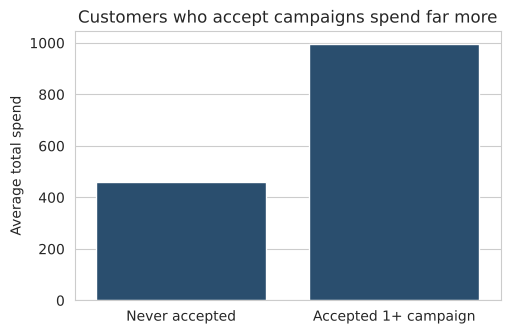

In [ ]:
# 59. SQL to Python link: chart from the SQL extract
x = sql_extract[(sql_extract['income'] < 600000) & (sql_extract['age'] <= 90)].copy()
x['accepted_any'] = np.where(x['campaigns_accepted'] > 0, 'Accepted 1+ campaign', 'Never accepted')
plt.figure(figsize=(5.5, 3.5))
sns.barplot(data=x, x='accepted_any', y='total_spend', color='#1F4E79', errorbar=None)
plt.title('Customers who accept campaigns spend far more')
plt.xlabel('')
plt.ylabel('Average total spend')
plt.show()